# Hands-on 14: Fitur Time-Series dari Data Suhu/Kelembaban

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 5.

Fitur yang dibangun dari `data/synthetic/room_30days.csv`: waktu dasar, encoding siklik jam,
lag (1 dan 6 langkah), difference, moving average, rolling statistics, dan comfort index
sederhana. Output: `data/processed/room_30days_features.csv` (25 kolom).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Bangun Fitur

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/feature_room_timeseries.py"], capture_output=True, text=True)
print(r.stdout)

Fitur time-series disimpan ke: data/processed/room_30days_features.csv
                    device_id  ...  comfort_index_simple
timestamp                      ...                      
2026-01-01 01:00:00    room01  ...                23.810
2026-01-01 01:10:00    room01  ...                24.166
2026-01-01 01:20:00    room01  ...                24.210
2026-01-01 01:30:00    room01  ...                25.770
2026-01-01 01:40:00    room01  ...                23.596

[5 rows x 25 columns]

Kolom fitur:
['device_id', 'temperature_c', 'humidity_pct', 'hour', 'day_of_week', 'is_weekend', 'hour_sin', 'hour_cos', 'temp_lag_1', 'temp_lag_6', 'hum_lag_1', 'hum_lag_6', 'temp_diff_1', 'temp_diff_6', 'hum_diff_1', 'temp_ma_3', 'temp_ma_6', 'hum_ma_3', 'temp_roll_std_6', 'temp_roll_min_6', 'temp_roll_max_6', 'hum_roll_std_6', 'hum_roll_min_6', 'hum_roll_max_6', 'comfort_index_simple']



## 2. Visualisasi Fitur

Figure(1200x500)



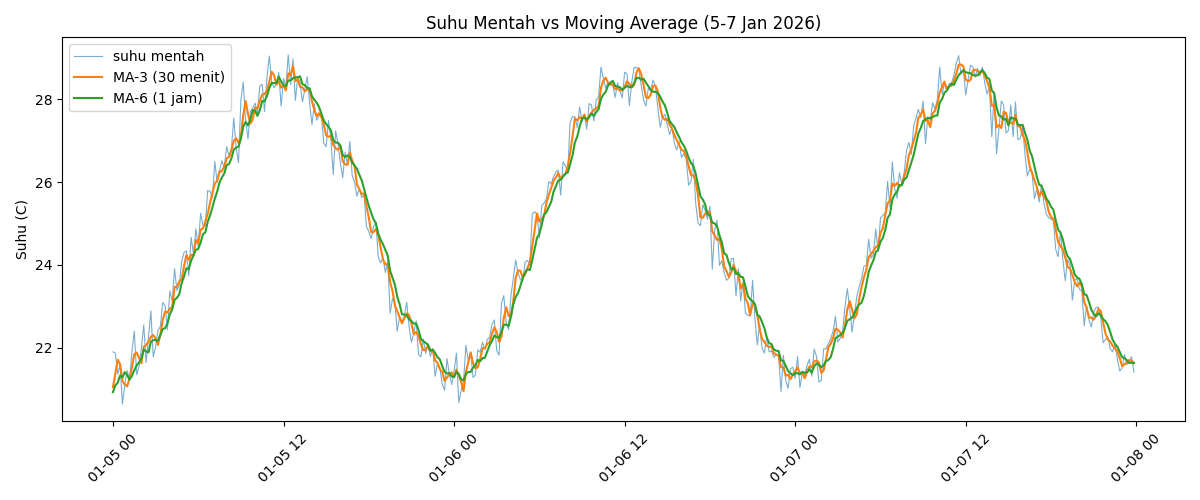

In [3]:
r = subprocess.run([sys.executable, "scripts/plot_room_features.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/features_moving_average.png")

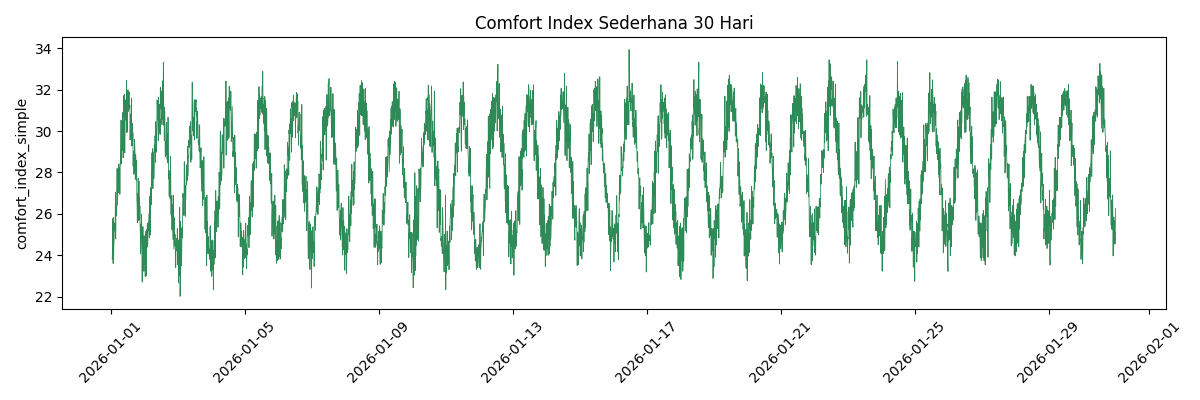

In [4]:
Image("outputs/figures/features_comfort_index.png")

## Penutup

25 kolom fitur siap dipakai model ML. Moving average menghaluskan noise harian, diff
menunjukkan laju perubahan, dan comfort index menggabungkan suhu-kelembaban. Fitur ini
dipakai pada Hands-on 23 (regresi) dan forecasting Bab 10.

## Figur persis sesuai buku (Hands-on 14)

`scripts/book_figures.py --only features` membuat `outputs/figures/room_temp_ma6.png` dengan judul, label sumbu, dan ukuran sesuai listing buku.

[SUKSES] figur 'features' dibuat di outputs/figures
 


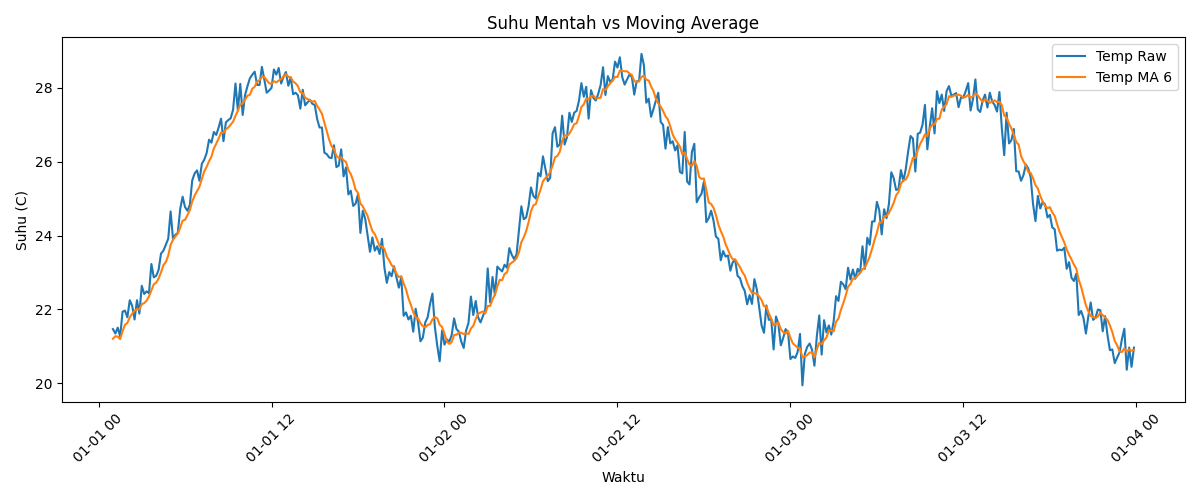

In [5]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/book_figures.py", "--only", "features"], capture_output=True, text=True)
print(r.stdout, r.stderr)
from IPython.display import Image, display
display(Image("outputs/figures/room_temp_ma6.png"))

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 14 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 8. Hasil yang harus diamati

Pembaca perlu melihat:

bagaimana moving average menghaluskan data,
bagaimana difference menangkap kenaikan atau penurunan cepat,
bagaimana fitur waktu memberi konteks pola harian,
bagaimana fitur gabungan bisa lebih bermakna daripada satu sensor tunggal.

## Jawaban dari data: Hasil yang harus diamati (Hands-on 14): jawaban dari data

In [6]:
import pandas as pd
df = pd.read_csv("data/processed/room_30days_features.csv", parse_dates=["timestamp"])
print("1. Moving average menghaluskan: std suhu mentah", round(df["temperature_c"].std(), 3), "-> std selisih mentah", round(df["temperature_c"].diff().std(), 3), "vs std selisih MA-6", round(df["temp_ma_6"].diff().std(), 3))
print("2. Difference menangkap perubahan cepat: |temp_diff_6| maks =", round(df["temp_diff_6"].abs().max(), 3))
print("3. Fitur waktu memberi konteks harian: rata-rata suhu per jam (jam 4 vs jam 14):", round(df[df.hour == 4].temperature_c.mean(), 2), "vs", round(df[df.hour == 14].temperature_c.mean(), 2))
print("4. Fitur gabungan comfort_index_simple: korelasi dengan suhu", round(df["comfort_index_simple"].corr(df["temperature_c"]), 3), ", dengan kelembaban", round(df["comfort_index_simple"].corr(df["humidity_pct"]), 3))

1. Moving average menghaluskan: std suhu mentah 2.53 -> std selisih mentah 0.499 vs std selisih MA-6 0.137
2. Difference menangkap perubahan cepat: |temp_diff_6| maks = 2.51
3. Fitur waktu memberi konteks harian: rata-rata suhu per jam (jam 4 vs jam 14): 23.71 vs 27.94
4. Fitur gabungan comfort_index_simple: korelasi dengan suhu 0.955 , dengan kelembaban -0.921
